# Quickr — Quick-Commerce Delivery Analytics

**Practical:** Big Data Analytics  
**Aim:** To analyse delivery data using PySpark RDD MapReduce, build a simple Random Forest regression model, and store the results in Apache Cassandra.

- Name: Arya Mahajan
- Class: B3
- Batch: B1
- Roll no: 03

Quickr is a quick-commerce delivery analytics project. This practical uses the actual file `data/raw/food_delivery.csv`. It contains delivery partner, order, weather, traffic, city, GPS and delivery-duration fields.

> The file has no price, quantity, product or category columns. Revenue and product-sales analysis are therefore not possible. This practical uses order counts, delivery duration and delivery performance instead.

## 1. Import Libraries

The practical needs PySpark for RDD operations, pandas for loading the CSV, and Matplotlib for simple charts.

In [1]:
from pyspark import SparkContext
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os
import sys
import json

## 2. Initialize SparkContext

Spark needs the same Python interpreter that is running this notebook. The project also has a local Hadoop helper for Windows.

In [2]:
ROOT = ".." if os.path.exists("../data/raw/food_delivery.csv") else "."
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
hadoop = os.path.abspath(f"{ROOT}/.hadoop")
if os.path.exists(f"{hadoop}/bin/winutils.exe"):
    os.environ["HADOOP_HOME"] = hadoop
print("Project path:", os.path.abspath(ROOT))

Project path: D:\Quickr


In [3]:
from pyspark import SparkConf, SparkContext
conf = SparkConf().setAppName("Quickr").setMaster("local[1]")
conf.set("spark.driver.memory", "640m")
conf.set("spark.ui.showConsoleProgress", "false")
sc = SparkContext.getOrCreate(conf)
sc.setLogLevel("ERROR")
print("Spark version:", sc.version)

Spark version: 3.5.3


## 3. Load the Dataset

The CSV is loaded with pandas. `raw_df` keeps a copy of the original data so the cleaning steps can be compared with the raw file.

In [4]:
df = pd.read_csv(f"{ROOT}/data/raw/food_delivery.csv")
raw_df = df.copy()
raw_rows = len(df)
raw_columns = len(df.columns)
print("Loaded rows:", raw_rows)
df.head()

Loaded rows:

 45593


,ID,Delivery_person_ID,Delivery_person_Age,Delivery_person_Ratings,Restaurant_latitude,Restaurant_longitude,Delivery_location_latitude,Delivery_location_longitude,Order_Date,Time_Orderd,Time_Order_picked,Weatherconditions,Road_traffic_density,Vehicle_condition,Type_of_order,Type_of_vehicle,multiple_deliveries,Festival,City,Time_taken(min)
0,0x4607,INDORES13DEL02,37,4.9,22.745049,75.892471,22.765049,75.912471,19-03-2022,11:30:00,11:45:00,conditions Sunny,High,2,Snack,motorcycle,0,No,Urban,(min) 24
1,0xb379,BANGRES18DEL02,34,4.5,12.913041,77.683237,13.043041,77.813237,25-03-2022,19:45:00,19:50:00,conditions Stormy,Jam,2,Snack,scooter,1,No,Metropolitian,(min) 33
2,0x5d6d,BANGRES19DEL01,23,4.4,12.914264,77.678400,12.924264,77.688400,19-03-2022,08:30:00,08:45:00,conditions Sandstorms,Low,0,Drinks,motorcycle,1,No,Urban,(min) 26
3,0x7a6a,COIMBRES13DEL02,38,4.7,11.003669,76.976494,11.053669,77.026494,05-04-2022,18:00:00,18:10:00,conditions Sunny,Medium,0,Buffet,motorcycle,1,No,Metropolitian,(min) 21
4,0x70a2,CHENRES12DEL01,32,4.6,12.972793,80.249982,13.012793,80.289982,26-03-2022,13:30:00,13:45:00,conditions Cloudy,High,1,Snack,scooter,1,No,Metropolitian,(min) 30


## 4. Inspect the Data

First I check the shape, column names, data types and a few values.

In [5]:
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
df.dtypes

Shape: (45593, 20)
Columns: ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']


ID                              object
Delivery_person_ID              object
Delivery_person_Age             object
Delivery_person_Ratings         object
Restaurant_latitude            float64
Restaurant_longitude           float64
Delivery_location_latitude     float64
Delivery_location_longitude    float64
Order_Date                      object
Time_Orderd                     object
Time_Order_picked               object
Weatherconditions               object
Road_traffic_density            object
Vehicle_condition                int64
Type_of_order                   object
Type_of_vehicle                 object
multiple_deliveries             object
Festival                        object
City                            object
Time_taken(min)                 object
dtype: object

In [6]:
df[["Delivery_person_Age", "Delivery_person_Ratings", "Weatherconditions", "Road_traffic_density", "City", "Time_taken(min)"]].head()
for col in ["Weatherconditions", "Road_traffic_density", "multiple_deliveries", "Festival", "City"]:
    print(col, df[col].astype(str).str.contains("NaN").sum())

Weatherconditions 616
Road_traffic_density 601
multiple_deliveries 993
Festival 228
City 1200


The target `Time_taken(min)` is stored as text, for example `(min) 24`. I extract the number and store it as `duration_min`.

In [7]:
df["duration_min"] = df["Time_taken(min)"].str.extract(r"(\d+)").astype(float)
df[["Time_taken(min)", "duration_min"]].head()

,Time_taken(min),duration_min
0,(min) 24,24.0
1,(min) 33,33.0
2,(min) 26,26.0
3,(min) 21,21.0
4,(min) 30,30.0


## 5. Create an RDD

I select the five useful columns and create an RDD with `sc.parallelize`.

In [8]:
cols = ["City", "Road_traffic_density", "Weatherconditions", "Type_of_vehicle", "duration_min"]
rows = df[cols].values.tolist()
rdd = sc.parallelize(rows, 4)
print("First rows:", rdd.take(3))

First rows: [['Urban ', 'High ', 'conditions Sunny', 'motorcycle ', 24.0], ['Metropolitian ', 'Jam ', 'conditions Stormy', 'scooter ', 33.0], ['Urban ', 'Low ', 'conditions Sandstorms', 'motorcycle ', 26.0]]


## 6. Simple MapReduce Analytics

The dataset has no price or quantity column, so total revenue cannot be calculated. The basic totals below use order count and total delivery minutes instead.

In [9]:
total_orders = rdd.count()
total_minutes = rdd.map(lambda x: x[4]).sum()
print("Total orders:", total_orders)
print("Total delivery minutes:", round(total_minutes, 2))
print("Average delivery minutes:", round(total_minutes / total_orders, 2))

Total orders: 45593
Total delivery minutes: 1198850.0
Average delivery minutes: 26.29


Orders are counted by city using `map` and `reduceByKey`.

In [10]:
city_counts = rdd.map(lambda x: (x[0].strip(), 1)).reduceByKey(lambda a, b: a + b)
print("Orders by city:", city_counts.collect())
print("Top cities:", city_counts.sortBy(lambda x: x[1], ascending=False).take(5))

Orders by city: [('Urban', 10136), ('NaN', 1200), ('Semi-Urban', 164), ('Metropolitian', 34093)]


Top cities: [('Metropolitian', 34093), ('Urban', 10136), ('NaN', 1200), ('Semi-Urban', 164)]


For delivery performance by category, each traffic value is mapped to `(total minutes, count)` and then reduced.

In [11]:
traffic_pairs = rdd.map(lambda x: (x[1].strip(), (x[4], 1)))
traffic_totals = traffic_pairs.reduceByKey(lambda a, b: (a[0] + b[0], a[1] + b[1]))
traffic_avg = traffic_totals.mapValues(lambda v: round(v[0] / v[1], 2))
print("Average minutes by traffic:", traffic_avg.collect())

Average minutes by traffic: [('Low', 21.27), ('Medium', 26.7), ('NaN', 26.54), ('Jam', 31.18), ('High', 27.24)]


In [12]:
weather_counts = rdd.map(lambda x: (x[2].strip(), 1)).reduceByKey(lambda a, b: a + b)
longest = rdd.max(key=lambda x: x[4])
shortest = rdd.min(key=lambda x: x[4])
print("Orders by weather:", weather_counts.collect())
print("Longest delivery:", longest)
print("Shortest delivery:", shortest)

Orders by weather: [('conditions Stormy', 7586), ('conditions Sunny', 7284), ('conditions Sandstorms', 7495), ('conditions Fog', 7654), ('conditions Windy', 7422), ('conditions Cloudy', 7536), ('conditions NaN', 616)]
Longest delivery: ['Semi-Urban ', 'Jam ', 'conditions Sandstorms', 'motorcycle ', 54.0]
Shortest delivery: ['Urban ', 'High ', 'conditions Windy', 'scooter ', 10.0]


## 7. Summary Statistics

Basic statistics give a quick idea of the delivery-duration distribution.

In [13]:
print(df["duration_min"].describe().round(2))
print(df["duration_min"].quantile([0.25, 0.5, 0.75, 0.9]).round(2))

count    45593.00
mean        26.29
std          9.38
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Name: duration_min, dtype: float64
0.25    19.0
0.50    26.0
0.75    32.0
0.90    40.0
Name: duration_min, dtype: float64


In [14]:
traffic_raw = df.assign(traffic=df["Road_traffic_density"].str.strip())
traffic_raw.groupby("traffic")["duration_min"].agg(["count", "mean", "median"]).round(2)

,count,mean,median
traffic,,,
High,4425,27.24,27.0
Jam,14143,31.18,31.0
Low,15477,21.27,20.0
Medium,10947,26.70,27.0
NaN,601,26.54,26.0


## 8. Basic Charts

The charts use the results calculated above. They are simple Matplotlib bar charts and a histogram.

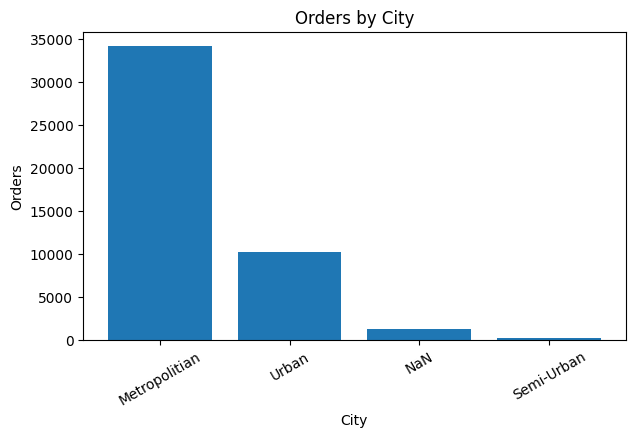

In [15]:
city_result = city_counts.sortBy(lambda x: x[1], ascending=False).take(8)
plt.figure(figsize=(7, 4))
plt.bar([x[0] for x in city_result], [x[1] for x in city_result])
plt.title("Orders by City")
plt.xlabel("City")
plt.ylabel("Orders")
plt.xticks(rotation=30)
plt.show()

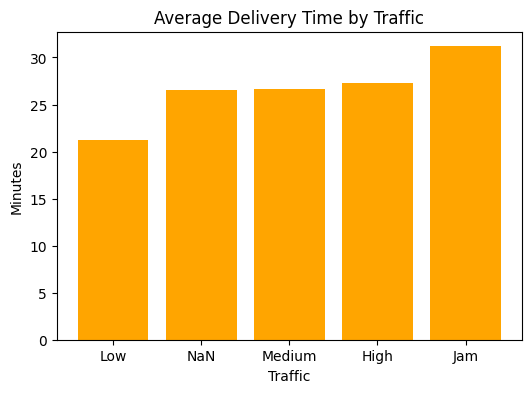

In [16]:
traffic_result = sorted(traffic_avg.collect(), key=lambda x: x[1])
plt.figure(figsize=(6, 4))
plt.bar([x[0] for x in traffic_result], [x[1] for x in traffic_result], color="orange")
plt.title("Average Delivery Time by Traffic")
plt.xlabel("Traffic")
plt.ylabel("Minutes")
plt.show()

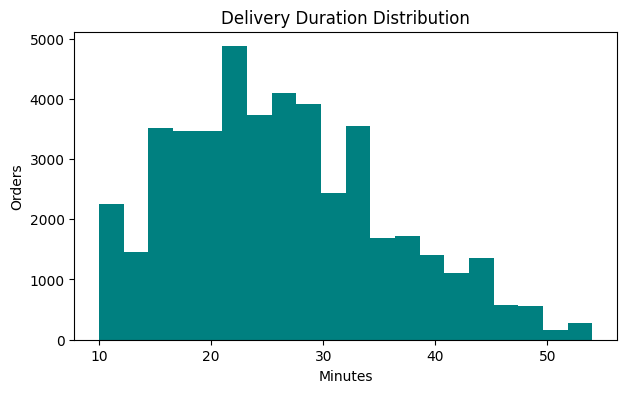

In [17]:
plt.figure(figsize=(7, 4))
plt.hist(df["duration_min"].dropna(), bins=20, color="teal")
plt.title("Delivery Duration Distribution")
plt.xlabel("Minutes")
plt.ylabel("Orders")
plt.show()

## 9. Clean the Data

The cleaning is kept simple: remove duplicates, fix text values, convert numeric columns, remove invalid duration/GPS records, and keep only usable categories. Counts are printed after each step.

In [18]:
duplicate_rows_removed = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
text_cols = ["Weatherconditions", "Road_traffic_density", "Type_of_order", "Type_of_vehicle", "Festival", "City"]
for col in text_cols:
    df[col] = df[col].str.strip()
df["Weatherconditions"] = df["Weatherconditions"].str.replace("conditions ", "", regex=False)
df["City"] = df["City"].replace("Metropolitian", "Metropolitan")
print("Duplicate rows removed:", duplicate_rows_removed)

Duplicate rows removed: 0


In [19]:
df = df.replace("NaN", np.nan)
for col in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")
print("Missing values after conversion:")
print(df[["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]].isna().sum())

Missing values after conversion:
Delivery_person_Age        1854
Delivery_person_Ratings    1908
multiple_deliveries         993
dtype: int64


In [20]:
invalid_target_rows = int((~df["duration_min"].between(1, 120)).sum())
df = df[df["duration_min"].between(1, 120)].copy()
print("Invalid duration rows removed:", invalid_target_rows)

Invalid duration rows removed: 0


In [21]:
gps_cols = ["Restaurant_latitude", "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude"]
gps_mask = df[gps_cols].notna().all(axis=1)
gps_mask &= df["Restaurant_latitude"].between(6, 37)
gps_mask &= df["Restaurant_longitude"].between(68, 98)
gps_mask &= df["Delivery_location_latitude"].between(6, 37)
gps_mask &= df["Delivery_location_longitude"].between(68, 98)
invalid_gps_rows = int((~gps_mask).sum())
df = df[gps_mask].copy()
print("Invalid GPS rows removed:", invalid_gps_rows)

Invalid GPS rows removed: 4071


In [22]:
lat1, lon1, lat2, lon2 = map(np.radians, [df[col] for col in gps_cols])
a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
df["distance_km"] = 2 * 6371 * np.arcsin(np.sqrt(a))
df["distance_km"].describe().round(2)

count    41522.00
mean         9.72
std          5.60
min          1.47
25%          4.66
50%          9.19
75%         13.68
max         20.97
Name: distance_km, dtype: float64

In [23]:
distance_outlier_rows = int((~df["distance_km"].between(0.1, 100)).sum())
df = df[df["distance_km"].between(0.1, 100)].copy()
missing_core_category_rows = int(df[["City", "Weatherconditions", "Road_traffic_density"]].isna().any(axis=1).sum())
df = df.dropna(subset=["City", "Weatherconditions", "Road_traffic_density"]).copy()
print("Distance outliers removed:", distance_outlier_rows)
print("Rows with missing category removed:", missing_core_category_rows)

Distance outliers removed:

 0
Rows with missing category removed: 1506


In [24]:
num_mask = df["Delivery_person_Age"].isna() | df["Delivery_person_Age"].between(18, 60)
num_mask &= (df["Delivery_person_Ratings"].isna() | df["Delivery_person_Ratings"].between(1, 5))
num_mask &= df["Vehicle_condition"].between(0, 3)
num_mask &= (df["multiple_deliveries"].isna() | df["multiple_deliveries"].between(0, 3))
invalid_numeric_rows = int((~num_mask).sum())
df = df[num_mask].copy()
print("Invalid numeric rows removed:", invalid_numeric_rows)

Invalid numeric rows removed: 0


In [25]:
excluded_total = raw_rows - len(df)
print("Raw rows:", raw_rows)
print("Clean rows:", len(df))
print("Excluded rows:", excluded_total)
df[["duration_min", "distance_km", "City", "Road_traffic_density"]].head()

Raw rows: 45593
Clean rows: 40016
Excluded rows: 5577


,duration_min,distance_km,City,Road_traffic_density
0,24.0,3.025149,Urban,High
1,33.0,20.183530,Metropolitan,Jam
2,26.0,1.552758,Urban,Low
3,21.0,7.790401,Metropolitan,Medium
4,30.0,6.210138,Metropolitan,High


The cleaned data now has a valid duration, a valid Indian route, and complete traffic, weather and city fields. Missing age, rating and concurrent-delivery values are kept and filled later inside the ML pipeline.

## 10. Additional Analytics

A delivery is called "late" if its duration is above the 75th percentile of the cleaned data. This is only an analytical label, not a customer promise.

In [26]:
late_threshold = df["duration_min"].quantile(0.75)
df["is_late"] = (df["duration_min"] > late_threshold).astype(int)
df["distance_band"] = pd.cut(df["distance_km"], bins=[0, 2, 5, 10, 20, 100], labels=["0-2 km", "2-5 km", "5-10 km", "10-20 km", "20+ km"], include_lowest=True)
df["age_band"] = pd.cut(df["Delivery_person_Age"], bins=[17, 24, 29, 34, 39, 60], labels=["18-24", "25-29", "30-34", "35-39", "40+"])
df["age_band"] = df["age_band"].cat.add_categories("Unknown").fillna("Unknown")
df["rating_band"] = pd.cut(df["Delivery_person_Ratings"], bins=[0, 4, 4.5, 4.8, 5.01], labels=["<4.0", "4.0-4.4", "4.5-4.7", "4.8-5.0"], include_lowest=True, right=False)
df["rating_band"] = df["rating_band"].cat.add_categories("Unknown").fillna("Unknown")
print("Late threshold:", late_threshold, "minutes")
print("Late rate:", round(df["is_late"].mean() * 100, 2), "%")
print(df[["distance_band", "age_band", "rating_band"]].head())

Late threshold: 33.0 minutes


Late rate: 22.3 %
  distance_band age_band rating_band
0        2-5 km    35-39     4.8-5.0
1        20+ km    30-34     4.5-4.7
2        0-2 km    18-24     4.0-4.4
3       5-10 km    35-39     4.5-4.7
4       5-10 km    30-34     4.5-4.7


### Category Summary

This small function calculates the number of deliveries, average duration, median, 90th percentile and late rate for each category.

In [27]:
def make_summary(column, name):
    table = df.groupby(column, observed=True).agg(
        deliveries=("duration_min", "count"),
        avg_duration_min=("duration_min", "mean"),
        median_duration_min=("duration_min", "median"),
        p90_duration_min=("duration_min", lambda x: x.quantile(0.9)),
        late_rate=("is_late", "mean"),
    ).reset_index()
    table["category_type"] = name
    table["category_value"] = table[column].astype(str)
    return table[["category_type", "category_value", "deliveries", "avg_duration_min", "median_duration_min", "p90_duration_min", "late_rate"]]

In [28]:
specs = [
    ("Road_traffic_density", "traffic"), ("Weatherconditions", "weather"),
    ("Type_of_vehicle", "vehicle"), ("City", "city"),
    ("Type_of_order", "order_type"), ("Festival", "festival"),
    ("distance_band", "distance_band"), ("age_band", "age_band"),
    ("rating_band", "rating_band"),
]
category_df = pd.concat([make_summary(col, name) for col, name in specs], ignore_index=True)
category_df = category_df.round(3)
print("Category summary rows:", len(category_df))

Category summary rows: 37


In [29]:
category_df["sort_order"] = 1
traffic_order = {"Low": 1, "Medium": 2, "High": 3, "Jam": 4}
category_df.loc[category_df["category_type"] == "traffic", "sort_order"] = category_df["category_value"].map(traffic_order).fillna(99).astype(int)
category_df.head(10)

,category_type,category_value,deliveries,avg_duration_min,median_duration_min,p90_duration_min,late_rate,sort_order
0,traffic,High,3951,27.291,27.0,38.0,0.190,3
1,traffic,Jam,12680,31.308,31.0,44.0,0.408,4
2,traffic,Low,13601,21.354,21.0,29.0,0.058,1
3,traffic,Medium,9784,26.811,27.0,38.0,0.226,2
4,weather,Cloudy,6722,29.032,29.0,43.0,0.347,1
5,weather,Fog,6802,29.117,29.0,43.0,0.357,1
6,weather,Sandstorms,6660,25.978,26.0,38.0,0.175,1
7,weather,Stormy,6749,26.014,26.0,38.0,0.176,1
8,weather,Sunny,6477,21.989,20.0,33.0,0.093,1
9,weather,Windy,6606,26.243,26.0,38.0,0.183,1


### Segment Summary

The dashboard uses a pre-aggregated table for traffic, weather, vehicle and city combinations. The 2-minute histogram is stored with each segment.

In [30]:
segment_keys = ["Road_traffic_density", "Weatherconditions", "Type_of_vehicle", "City"]
segment_df = df.groupby(segment_keys).agg(
    deliveries=("duration_min", "count"),
    avg_duration_min=("duration_min", "mean"),
    median_duration_min=("duration_min", "median"),
    p90_duration_min=("duration_min", lambda x: x.quantile(0.9)),
    late_rate=("is_late", "mean"),
).reset_index()
segment_df = segment_df.round(3)
print("Segment rows:", len(segment_df))

Segment rows: 163


In [31]:
df["bucket_start_min"] = (df["duration_min"] // 2 * 2).astype(int)
bucket_map = lambda s: {int(k): int(v) for k, v in s.value_counts().items()}
histogram_df = df.groupby(segment_keys).agg(histogram=("bucket_start_min", bucket_map)).reset_index()
segment_df = segment_df.merge(histogram_df, on=segment_keys)
print("Histogram added to segments:", len(segment_df))

Histogram added to segments: 163


In [32]:
distribution_df = df.groupby("bucket_start_min").size().reset_index(name="delivery_count")
distribution_df["bucket_label"] = distribution_df["bucket_start_min"].apply(lambda x: f"{x}-{x + 2} min")
distribution_df.head()

,bucket_start_min,delivery_count,bucket_label
0,10,1281,10-12 min
1,12,1253,12-14 min
2,14,2155,14-16 min
3,16,2959,16-18 min
4,18,3086,18-20 min


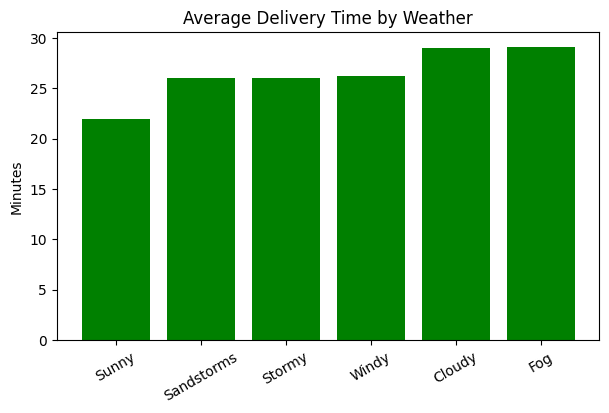

In [33]:
weather_avg = df.groupby("Weatherconditions")["duration_min"].mean().sort_values()
plt.figure(figsize=(7, 4))
plt.bar(weather_avg.index, weather_avg.values, color="green")
plt.title("Average Delivery Time by Weather")
plt.ylabel("Minutes")
plt.xticks(rotation=30)
plt.show()

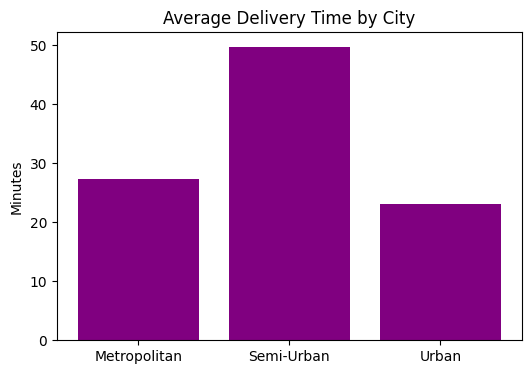

In [34]:
city_avg = df.groupby("City")["duration_min"].mean()
plt.figure(figsize=(6, 4))
plt.bar(city_avg.index, city_avg.values, color="purple")
plt.title("Average Delivery Time by City")
plt.ylabel("Minutes")
plt.show()

## 11. Random Forest Regression

The target `duration_min` is a valid numerical field, so a Random Forest Regressor is used. Only pre-delivery fields are used as input. The preprocessing and model are kept in a scikit-learn pipeline so the saved model can also be used by the dashboard.

In [35]:
num_cols = ["Delivery_person_Age", "Delivery_person_Ratings", "distance_km", "Vehicle_condition", "multiple_deliveries"]
cat_cols = ["Weatherconditions", "Road_traffic_density", "Type_of_order", "Type_of_vehicle", "Festival", "City"]
features = num_cols + cat_cols
from sklearn.model_selection import train_test_split
X = df[features]
y = df["duration_min"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Features used:", len(features), "Train rows:", len(X_train), "Test rows:", len(X_test))

Features used: 11 Train rows: 32012 Test rows: 8004


In [36]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
num_step = Pipeline([("imputer", SimpleImputer(strategy="median"))])
cat_step = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))])
preprocess = ColumnTransformer([("num", num_step, num_cols), ("cat", cat_step, cat_cols)])

In [37]:
from sklearn.ensemble import RandomForestRegressor
model = Pipeline([
    ("preprocess", preprocess),
    ("forest", RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1)),
])
model.fit(X_train, y_train)
print("Random Forest trained")

Random Forest trained


In [38]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
y_pred = model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test - y_pred) / y_test))
print("MAE:", round(mae, 2), "RMSE:", round(rmse, 2), "R2:", round(r2, 3))
print("MAPE:", round(mape * 100, 2), "%")

MAE: 3.13 RMSE: 3.92 R2: 0.819
MAPE: 13.47 %


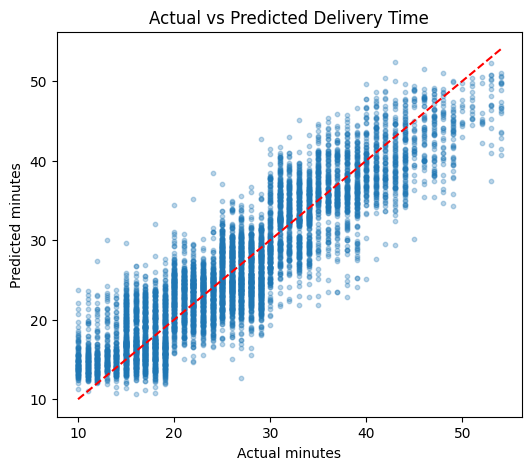

In [39]:
plt.figure(figsize=(6, 5))
plt.scatter(y_test, y_pred, alpha=0.3, s=10)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], "r--")
plt.title("Actual vs Predicted Delivery Time")
plt.xlabel("Actual minutes")
plt.ylabel("Predicted minutes")
plt.show()

The model is evaluated on a 20% holdout split. The printed MAE and RMSE are in minutes. These values are calculated from the actual CSV, not typed into the notebook.

## 12. Save Analytical Results

The cleaned data, category summary, segment summary, distribution and model files are saved for inspection and for the Streamlit dashboard.

In [40]:
os.makedirs(f"{ROOT}/data/processed/analytics", exist_ok=True)
os.makedirs(f"{ROOT}/models", exist_ok=True)
df.to_csv(f"{ROOT}/data/processed/quickr_clean.csv", index=False)
category_df.to_csv(f"{ROOT}/data/processed/analytics/category_summary.csv", index=False)
segment_df.to_csv(f"{ROOT}/data/processed/analytics/segment_summary.csv", index=False)
distribution_df.to_csv(f"{ROOT}/data/processed/analytics/duration_distribution.csv", index=False)
print("Analytical CSVs saved")

Analytical CSVs saved


In [41]:
categorical_options = {col: sorted(df[col].dropna().astype(str).unique().tolist()) for col in cat_cols}
numeric_ranges = {col: {"min": float(df[col].min()), "max": float(df[col].max())} for col in num_cols}
default_values = {col: float(df[col].median()) for col in num_cols}
default_values.update({col: float(df[col].median()) for col in gps_cols})
print("Dashboard input defaults ready")

Dashboard input defaults ready


In [42]:
model_metadata = {
    "model_name": "Random Forest",
    "model_version": "1.0",
    "target": "delivery duration in minutes",
    "target_unit": "minutes",
    "training_rows": len(X_train),
    "test_rows": len(X_test),
    "feature_order": features,
    "random_seed": 42,
}
print("Base metadata ready")

Base metadata ready


In [43]:
model_metadata["numeric_features"] = num_cols
model_metadata["categorical_features"] = cat_cols
model_metadata["categorical_options"] = categorical_options
model_metadata["numeric_ranges"] = numeric_ranges
model_metadata["default_values"] = default_values
model_metadata["late_threshold_min"] = float(late_threshold)
model_metadata["split_method"] = "80/20 random holdout, random_state=42"
model_metadata["run_id"] = pd.Timestamp.utcnow().strftime("%Y%m%dT%H%M%SZ")
model_metadata["metrics"] = {"mae": float(mae), "rmse": float(rmse), "r2": float(r2), "mape": float(mape)}
print("Metadata complete")

Metadata complete


In [44]:
import joblib
bundle = {"pipeline": model, "metadata": model_metadata}
joblib.dump(bundle, f"{ROOT}/models/quickr_delivery_time_model.joblib")
with open(f"{ROOT}/models/model_metadata.json", "w") as f:
    json.dump(model_metadata, f, indent=2)
test_predictions = pd.DataFrame({"actual_min": y_test, "predicted_min": y_pred})
test_predictions.to_csv(f"{ROOT}/models/test_predictions.csv", index=False)
metrics = {"model": "Random Forest", "mae": float(mae), "rmse": float(rmse), "r2": float(r2), "mape": float(mape)}
with open(f"{ROOT}/models/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
print("Model, predictions and metrics saved")

Model, predictions and metrics saved


## 13. Delivery Performance Scorecard

The target is `duration_min`, parsed from `(min) 24`. Only durations that passed the cleaning rule (1–120 minutes) are used. The source has no promised deadline, so the threshold is an analytical duration cutoff, not an SLA.

In [45]:
valid_durations = df["duration_min"]
avg_duration = float(valid_durations.mean())
median_duration = float(valid_durations.median())
min_duration = float(valid_durations.min())
max_duration = float(valid_durations.max())
print("Valid records:", len(valid_durations))
print("Average / median:", round(avg_duration, 2), "/", median_duration)
print("Fastest / slowest:", min_duration, "/", max_duration)


Valid records: 40016
Average / median: 26.43 / 26.0
Fastest / slowest: 10.0 / 54.0


In [46]:
score_threshold = int(round(late_threshold))
above_count = int((valid_durations > score_threshold).sum())
above_pct = above_count / len(valid_durations)
print("Documented threshold:", score_threshold, "minutes")
print("Above threshold:", above_count, f"({above_pct:.2%})")


Documented threshold: 33 minutes
Above threshold: 8922 (22.30%)


In [47]:
threshold_rows = []
for threshold in range(1, int(np.ceil(max_duration)) + 1):
    count = int((valid_durations > threshold).sum())
    threshold_rows.append({"threshold_min": threshold, "deliveries_above": count,
                           "valid_deliveries": len(valid_durations),
                           "above_pct": count / len(valid_durations)})
threshold_df = pd.DataFrame(threshold_rows)
threshold_df.head()


,threshold_min,deliveries_above,valid_deliveries,above_pct
0,1,40016,40016,1.0
1,2,40016,40016,1.0
2,3,40016,40016,1.0
3,4,40016,40016,1.0
4,5,40016,40016,1.0


## 14. Delivery Risk Classifier

No promised deadline or official late label exists. The positive class is `duration_min > P75` of the training split only. This is a duration-risk proxy, not an SLA. The same 80/20 split as the regressor is used. The split is not stratified because the label can only be defined after the training split; both class rates are reported. The target is excluded from the inputs.

In [48]:
risk_threshold = float(y_train.quantile(0.75))
y_train_late = (y_train > risk_threshold).astype(int)
y_test_late = (y_test > risk_threshold).astype(int)
print("Training-only threshold:", risk_threshold, "minutes")
print("Train positives:", int(y_train_late.sum()), "of", len(y_train_late))
print("Test positives:", int(y_test_late.sum()), "of", len(y_test_late))


Training-only threshold: 33.0 minutes
Train positives: 7228 of 32012
Test positives: 1694 of 8004


In [49]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix
risk_preprocess = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num_cols),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")), ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols),
])
risk_model = Pipeline([("preprocess", risk_preprocess),
                       ("model", LogisticRegression(max_iter=1000, random_state=42))])
risk_model.fit(X_train, y_train_late)
print("Risk classifier trained")


Risk classifier trained


In [50]:
risk_prob = risk_model.predict_proba(X_test)[:, 1]
risk_pred = (risk_prob >= 0.5).astype(int)
risk_accuracy = accuracy_score(y_test_late, risk_pred)
risk_precision = precision_score(y_test_late, risk_pred, zero_division=0)
risk_recall = recall_score(y_test_late, risk_pred, zero_division=0)
risk_f1 = f1_score(y_test_late, risk_pred, zero_division=0)
risk_auc = roc_auc_score(y_test_late, risk_prob)
print("Accuracy:", round(risk_accuracy, 3), "Precision:", round(risk_precision, 3))
print("Recall:", round(risk_recall, 3), "F1:", round(risk_f1, 3), "ROC-AUC:", round(risk_auc, 3))


Accuracy: 0.874 Precision: 0.729
Recall: 0.64 F1: 0.682 ROC-AUC: 0.925


In [51]:
risk_cm = confusion_matrix(y_test_late, risk_pred)
tn, fp, fn, tp = risk_cm.ravel()
print("Confusion matrix:")
print(risk_cm)
print("TN / FP / FN / TP:", tn, fp, fn, tp)


Confusion matrix:
[[5908  402]
 [ 610 1084]]
TN / FP / FN / TP: 5908 402 610 1084


In [52]:
medium_threshold = 0.40
high_threshold = 0.65
bands = {"Low": risk_prob < medium_threshold,
         "Medium": (risk_prob >= medium_threshold) & (risk_prob < high_threshold),
         "High": risk_prob >= high_threshold}
for name, mask in bands.items():
    print(name, int(mask.sum()), f"({mask.mean():.1%} of test records)")


Low 6244 (78.0% of test records)
Medium 657 (8.2% of test records)
High 1103 (13.8% of test records)


The score bands are display groups, not calibrated probabilities. They are configurable in the dashboard; the default values are stored with the model.

In [53]:
risk_metadata = {
    "model_name": "Logistic Regression", "model_version": "1.0",
    "target": "above training-only P75 delivery duration",
    "target_unit": "risk band", "training_rows": len(X_train),
    "test_rows": len(X_test), "feature_order": features,
    "numeric_features": num_cols, "categorical_features": cat_cols,
    "categorical_options": categorical_options, "numeric_ranges": numeric_ranges,
    "default_values": default_values,
}
print("Risk metadata part 1 ready")


Risk metadata part 1 ready


In [54]:
risk_metadata.update({
    "late_threshold_min": risk_threshold, "medium_threshold": medium_threshold,
    "high_threshold": high_threshold, "probability_threshold": 0.5,
    "random_seed": 42, "split_method": "80/20 random holdout, random_state=42",
})
print("Risk metadata complete")


Risk metadata complete


In [55]:
risk_bundle = {"pipeline": risk_model, "metadata": risk_metadata,
               "late_threshold_min": risk_threshold, "classification_threshold": 0.5}
joblib.dump(risk_bundle, f"{ROOT}/models/quickr_delay_risk_model.joblib")
pd.DataFrame(risk_cm, index=["Actual below", "Actual above"],
             columns=["Predicted below", "Predicted above"]).to_csv(
    f"{ROOT}/models/confusion_matrix.csv")
print("Risk model and confusion matrix saved")


Risk model and confusion matrix saved


In [56]:
risk_metrics = {
    "model": "Logistic Regression", "accuracy": float(risk_accuracy),
    "precision": float(risk_precision), "recall": float(risk_recall),
    "f1": float(risk_f1), "roc_auc": float(risk_auc),
    "test_rows": len(X_test), "train_rows": len(X_train),
    "train_positive_rate": float(y_train_late.mean()),
    "test_positive_rate": float(y_test_late.mean()),
    "threshold_min": float(risk_threshold), "probability_threshold": 0.5,
    "medium_threshold": medium_threshold, "high_threshold": high_threshold,
}
with open(f"{ROOT}/models/risk_metrics.json", "w") as f:
    json.dump(risk_metrics, f, indent=2)
print("Risk metrics saved")


Risk metrics saved


The saved `quickr_delivery_time_model.joblib` contains the complete pipeline, so the dashboard can pass raw input fields without repeating the preprocessing.

## 15. Cassandra Integration

Cassandra runs locally on port **9043**. The notebook reuses the checked-in `cassandra/schema.cql` file and writes the same tables that the Streamlit dashboard reads.

In [57]:
CASSANDRA_HOST = os.getenv("CASSANDRA_HOST", "127.0.0.1")
CASSANDRA_PORT = int(os.getenv("CASSANDRA_PORT", "9043"))
CASSANDRA_KEYSPACE = os.getenv("CASSANDRA_KEYSPACE", "quickr")
updated_at = pd.Timestamp.utcnow().tz_localize(None).to_pydatetime()
from cassandra.cluster import Cluster
cluster = Cluster([CASSANDRA_HOST], port=CASSANDRA_PORT)
session = cluster.connect()
print("Connected to Cassandra:", CASSANDRA_HOST, CASSANDRA_PORT, CASSANDRA_KEYSPACE)

Connected to Cassandra: 127.0.0.1 9043 quickr


In [58]:
schema = open(f"{ROOT}/cassandra/schema.cql").read()
schema = "\n".join(line for line in schema.splitlines() if not line.strip().startswith("--"))
for statement in schema.split(";"):
    if not statement.strip() or statement.strip().upper().startswith("USE"):
        continue
    session.execute(statement)
    if statement.strip().upper().startswith("CREATE KEYSPACE"):
        session.set_keyspace(CASSANDRA_KEYSPACE)
for table in ["delivery_summary_by_category", "delivery_segment_summary", "delivery_duration_distribution", "delivery_duration_thresholds", "delivery_metrics"]:
    session.execute(f"TRUNCATE {table}")
print("Cassandra tables ready and old analytics cleared")

Cassandra tables ready and old analytics cleared


The category summary is written row by row using a prepared statement. This small table makes the dashboard's category charts easy to query.

In [59]:
insert_category = session.prepare(
    "INSERT INTO delivery_summary_by_category "
    "(category_type, category_value, deliveries, avg_duration_min, median_duration_min, "
    "p90_duration_min, late_rate, sort_order, updated_at) "
    "VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?)"
)
print("Category insert statement ready")

Category insert statement ready


In [60]:
for row in category_df.itertuples():
    session.execute(insert_category, (
        row.category_type, row.category_value, int(row.deliveries),
        float(row.avg_duration_min), float(row.median_duration_min),
        float(row.p90_duration_min), float(row.late_rate),
        int(row.sort_order), updated_at))
print("Category rows written:", len(category_df))

Category rows written: 37


The segment summary includes the histogram map for the dashboard's interactive filters.

In [61]:
insert_segment = session.prepare(
    "INSERT INTO delivery_segment_summary "
    "(traffic_level, weather, vehicle_type, city, deliveries, avg_duration_min, "
    "median_duration_min, p90_duration_min, late_rate, histogram, updated_at) "
    "VALUES (?, ?, ?, ?, ?, ?, ?, ?, ?, ?, ?)"
)
print("Segment insert statement ready")

Segment insert statement ready


In [62]:
for row in segment_df.itertuples():
    session.execute(insert_segment, (
        row.Road_traffic_density, row.Weatherconditions, row.Type_of_vehicle, row.City,
        int(row.deliveries), float(row.avg_duration_min), float(row.median_duration_min),
        float(row.p90_duration_min), float(row.late_rate), row.histogram, updated_at))
print("Segment rows written:", len(segment_df))

Segment rows written: 163


In [63]:
insert_distribution = session.prepare("INSERT INTO delivery_duration_distribution (bucket_start_min, bucket_label, delivery_count, updated_at) VALUES (?, ?, ?, ?)")
for row in distribution_df.itertuples():
    session.execute(insert_distribution, (int(row.bucket_start_min), row.bucket_label, int(row.delivery_count), updated_at))
print("Distribution rows written:", len(distribution_df))

Distribution rows written: 23


In [64]:
insert_threshold = session.prepare(
    "INSERT INTO delivery_duration_thresholds "
    "(threshold_min, deliveries_above, valid_deliveries, above_pct, updated_at) "
    "VALUES (?, ?, ?, ?, ?)"
)
for row in threshold_df.itertuples():
    session.execute(insert_threshold, (int(row.threshold_min), int(row.deliveries_above),
                    int(row.valid_deliveries), float(row.above_pct), updated_at))
print("Threshold rows written:", len(threshold_df))


Threshold rows written: 54


Finally, the measured data-quality and model metrics are written to the small `delivery_metrics` table.

In [65]:
missing_values = {col: int(raw_df[col].astype(str).str.contains("NaN", na=False).sum()) for col in ["Weatherconditions", "Road_traffic_density", "multiple_deliveries", "Festival", "City"]}
remaining_missing = {col: int(df[col].isna().sum()) for col in ["Delivery_person_Age", "Delivery_person_Ratings", "multiple_deliveries"]}
print("Raw missing markers:", missing_values)
print("Missing after cleaning:", remaining_missing)

Raw missing markers: {'Weatherconditions': 616, 'Road_traffic_density': 601, 'multiple_deliveries': 993, 'Festival': 228, 'City': 1200}
Missing after cleaning: {'Delivery_person_Age': 1067, 'Delivery_person_Ratings': 1105, 'multiple_deliveries': 859}


In [66]:
cleaning_counts = {
    "raw_rows": raw_rows, "raw_columns": raw_columns,
    "duplicate_rows_removed": duplicate_rows_removed,
    "invalid_target_rows": invalid_target_rows,
    "invalid_gps_rows": invalid_gps_rows,
    "distance_outlier_rows": distance_outlier_rows,
    "missing_core_category_rows": missing_core_category_rows,
    "invalid_numeric_rows": invalid_numeric_rows,
    "excluded_total": excluded_total,
    "final_rows": len(df),
}
print("Cleaning counts ready")

Cleaning counts ready


In [67]:
cleaning_counts.update({
    "avg_duration_min": float(df["duration_min"].mean()),
    "median_duration_min": float(df["duration_min"].median()),
    "p90_duration_min": float(df["duration_min"].quantile(0.9)),
    "late_threshold_min": float(late_threshold),
    "late_rate": float(df["is_late"].mean()),
    "train_rows": len(X_train),
    "test_rows": len(X_test),
})
print("Summary metrics added")

Summary metrics added


In [68]:
date_range = f"{df['Order_Date'].min()} to {df['Order_Date'].max()}"
dataset_info = {
    "raw_filename": "data/raw/food_delivery.csv",
    "source_url": "https://github.com/koushik-Devs/Food_Delivery_Time_Prediction",
    "license": "No explicit license file; used for academic analysis only.",
    "target": "Time_taken(min) parsed to duration_min",
    "date_range": date_range,
    "limitations": "No price/quantity; timestamps incomplete; straight-line distance; associations only.",
    "schema": ", ".join(f"{col}:{raw_df[col].dtype}" for col in raw_df.columns),
}
print("Dataset notes ready")

Dataset notes ready


In [69]:
metric_rows = []
for name, value in cleaning_counts.items():
    metric_rows.append({"metric_group": "data_quality", "metric_name": name, "metric_value": float(value)})
for name, value in missing_values.items():
    metric_rows.append({"metric_group": "missing_values", "metric_name": name, "metric_value": float(value)})
for name, value in remaining_missing.items():
    metric_rows.append({"metric_group": "missing_values_after_cleaning", "metric_name": name, "metric_value": float(value)})
print("Quality metric rows:", len(metric_rows))

Quality metric rows: 25


In [70]:
for name in ["mae", "rmse", "r2", "mape"]:
    metric_rows.append({
        "metric_group": "model_performance",
        "metric_name": f"Random Forest.{name}",
        "metric_value": float(metrics[name]),
        "model_name": "Random Forest",
        "model_version": "1.0",
    })
print("Model metric rows added")

Model metric rows added


In [71]:
for name, text in dataset_info.items():
    metric_rows.append({"metric_group": "dataset", "metric_name": name, "metric_text": text})
metric_rows.append({"metric_group": "app_meta", "metric_name": "best_model", "metric_value": float(rmse), "metric_text": "Random Forest", "model_name": "Random Forest", "model_version": "1.0"})
metric_rows.append({"metric_group": "app_meta", "metric_name": "model_version", "metric_text": "1.0"})
metric_rows.append({"metric_group": "app_meta", "metric_name": "generated_at", "metric_text": str(pd.Timestamp.now())})
print("Dataset and app metric rows added")

Dataset and app metric rows added


In [72]:
extra_quality = {
    "min_duration_min": min_duration, "max_duration_min": max_duration,
    "above_threshold_count": float(above_count),
    "above_threshold_pct": float(above_pct),
    "score_threshold_min": float(score_threshold),
}
for name, value in extra_quality.items():
    metric_rows.append({"metric_group": "data_quality", "metric_name": name,
                        "metric_value": float(value)})
print("Scorecard metric rows added:", len(extra_quality))


Scorecard metric rows added: 5


In [73]:
risk_values = {
    "accuracy": risk_accuracy, "precision": risk_precision, "recall": risk_recall,
    "f1": risk_f1, "roc_auc": risk_auc, "probability_threshold": 0.5,
    "threshold_min": risk_threshold, "training_threshold_min": risk_threshold,
    "train_positive_rate": y_train_late.mean(), "test_positive_rate": y_test_late.mean(),
    "train_rows": len(X_train), "test_rows": len(X_test),
    "train_positives": int(y_train_late.sum()), "test_positives": int(y_test_late.sum()),
    "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
    "predicted_positive_rate": float(risk_pred.mean()),
    "medium_threshold": medium_threshold, "high_threshold": high_threshold,
}
print("Risk metric rows ready:", len(risk_values))


Risk metric rows ready: 21


In [74]:
for name, value in risk_values.items():
    metric_rows.append({"metric_group": "delay_risk_performance", "metric_name": name,
                        "metric_value": float(value), "model_name": "Logistic Regression",
                        "model_version": "1.0"})
metric_rows.append({"metric_group": "delay_risk_performance", "metric_name": "threshold_definition",
                    "metric_text": "Positive class = actual duration > P75 of training durations; "
                                   "duration-risk proxy, not an SLA", "model_name": "Logistic Regression",
                    "model_version": "1.0"})
metric_rows.append({"metric_group": "app_meta", "metric_name": "risk_model",
                    "metric_text": "Logistic Regression", "model_name": "Logistic Regression",
                    "model_version": "1.0"})
print("Risk metric rows added")


Risk metric rows added


In [75]:
metrics_df = pd.DataFrame(metric_rows)
metrics_df = metrics_df.astype(object).where(pd.notna(metrics_df), None)
metrics_df["evaluated_at"] = pd.Timestamp.utcnow().tz_localize(None)
metrics_df.to_csv(f"{ROOT}/data/processed/analytics/delivery_metrics.csv", index=False)
metrics_df.head()

,metric_group,metric_name,metric_value,model_name,model_version,metric_text,evaluated_at
0,data_quality,raw_rows,45593.0,None,None,None,2026-10-21 19:30:30.374726
1,data_quality,raw_columns,20.0,None,None,None,2026-10-21 19:30:30.374726
2,data_quality,duplicate_rows_removed,0.0,None,None,None,2026-10-21 19:30:30.374726
3,data_quality,invalid_target_rows,0.0,None,None,None,2026-10-21 19:30:30.374726
4,data_quality,invalid_gps_rows,4071.0,None,None,None,2026-10-21 19:30:30.374726


In [76]:
insert_metric = session.prepare("INSERT INTO delivery_metrics (metric_group, metric_name, metric_value, metric_text, model_name, model_version, evaluated_at) VALUES (?, ?, ?, ?, ?, ?, ?)")
for row in metrics_df.itertuples():
    session.execute(insert_metric, (row.metric_group, row.metric_name, row.metric_value, row.metric_text, row.model_name, row.model_version, row.evaluated_at))
print("Metric rows written:", len(metrics_df))

Metric rows written: 67


### Read Back the Stored Results

The rows are read back with the Python Cassandra driver to confirm that the writes succeeded.

In [77]:
rows = session.execute("SELECT category_type, category_value, avg_duration_min FROM delivery_summary_by_category WHERE category_type = 'traffic'")
for row in rows:
    print(row[0], row[1], round(row[2], 2))
tables = ["delivery_summary_by_category", "delivery_segment_summary", "delivery_duration_distribution", "delivery_duration_thresholds", "delivery_metrics"]
for table in tables:
    print(table, session.execute(f"SELECT COUNT(*) FROM {table}").one()[0])

traffic High 27.29
traffic Jam 31.31
traffic Low 21.35
traffic Medium 26.81
delivery_summary_by_category 37
delivery_segment_summary 163
delivery_duration_distribution 23
delivery_duration_thresholds 54
delivery_metrics 67


In [78]:
cluster.shutdown()
print("Cassandra connection closed")

Cassandra connection closed


In [79]:
sc.stop()
print("Spark stopped")

Spark stopped


## 16. Conclusion

- The raw CSV had **45,593** rows and **20** columns. After cleaning, **40,016** rows remained for analysis.
- The dataset has no price, quantity, product or category fields, so revenue and product-sales analysis were replaced with order-count and delivery-duration analysis.
- The scorecard measured a **26.43-minute average**, a **26.0-minute median**, a **10-minute fastest** delivery, and a **54-minute slowest** delivery.
- **8,922 deliveries (22.30%)** exceeded the documented **33-minute** analytical threshold. This is a duration cutoff, not an official late-delivery rate, because no promised deadline exists.
- The Random Forest regressor achieved **MAE ≈ 3.13 minutes**, **RMSE ≈ 3.92 minutes**, and **R² ≈ 0.82** on the held-out 20% split.
- The Logistic Regression risk classifier used a training-only P75 label of **33 minutes**. On the held-out split it achieved **accuracy 0.874**, **precision 0.729**, **recall 0.640**, **F1 0.682**, and **ROC-AUC 0.925**.
- The risk score is an uncalibrated, duration-based proxy. The dashboard shows Low/Medium/High bands and explains that this is not a customer SLA.
- The category summaries, segment cube, duration distribution, exact threshold counts, model metrics, and model files were saved. The same results were written to Cassandra and read back successfully.
- The models use only pre-delivery fields. Straight-line distance, missing live traffic, and incomplete timestamps are limitations of this dataset.
